<h3 style="color:white">EV Charging Demand Classification</h3>

In [23]:
import pandas as pd

df = pd.read_csv("../data/processed/ChargingRecords_cleaned.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (72826, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81


<h3 style="color:white">Create High and Normal Demand Labels</h3>

In [24]:
threshold = df["Demand"].median()

df["Demand_Level"] = (df["Demand"] >= threshold).astype(int)

print("Demand Threshold:", threshold)
print("\nDemand Level Counts:")
print(df["Demand_Level"].value_counts())

print("\nLabel Meaning:")
print("0 = Normal Demand")
print("1 = High Demand")

Demand Threshold: 14.1

Demand Level Counts:
Demand_Level
1    36439
0    36387
Name: count, dtype: int64

Label Meaning:
0 = Normal Demand
1 = High Demand


<h3 style="color:white">Classification Features</h3>

In [25]:
X = df[[
    "UserID",
    "ChargerID",
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Duration"
]]

y = df["Demand_Level"]

X = pd.get_dummies(X, columns=["Location"], dtype=int)

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (72826, 19)
Target Shape: (72826,)


<h3 style="color:white">Split Training and Testing Data</h3>

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (58260, 19)
Testing Features: (14566, 19)
Training Target: (58260,)
Testing Target: (14566,)


<h3 style="color:white">Train Logistic Regression Model</h3>

In [40]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


d:\anaconda_python\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(max_iter=2000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


<h3 style="color:white">Evaluate Logistic Regression Model</h3>

In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8342
Precision: 0.8188
Recall: 0.8587
F1-Score: 0.8383
ROC-AUC: 0.9077

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.81      0.83      7278
           1       0.82      0.86      0.84      7288

    accuracy                           0.83     14566
   macro avg       0.84      0.83      0.83     14566
weighted avg       0.83      0.83      0.83     14566



<h3 style="color:white">Train Decision Tree Classifier</h3>

In [44]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


<h3 style="color:white">Evaluate Decision Tree Classifier</h3>

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall:", round(recall_score(y_test, y_pred_dt), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_dt), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_dt), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.9156
Precision: 0.8888
Recall: 0.9501
F1-Score: 0.9184
ROC-AUC: 0.96

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.88      0.91      7278
           1       0.89      0.95      0.92      7288

    accuracy                           0.92     14566
   macro avg       0.92      0.92      0.92     14566
weighted avg       0.92      0.92      0.92     14566



<h3 style="color:white">Train Random Forest Classifier</h3>

In [46]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


<h3 style="color:white">Evaluate Random Forest Classifier</h3>

In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.9325
Precision: 0.9272
Recall: 0.9388
F1-Score: 0.933
ROC-AUC: 0.978

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      7278
           1       0.93      0.94      0.93      7288

    accuracy                           0.93     14566
   macro avg       0.93      0.93      0.93     14566
weighted avg       0.93      0.93      0.93     14566



<h3 style="color:white">Classification Model Comparison</h3>

In [48]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

classification_results = classification_results.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

classification_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9325,0.9272,0.9388,0.9330,0.9780
1,Decision Tree,0.9156,0.8888,0.9501,0.9184,0.9600
2,Logistic Regression,0.8342,0.8188,0.8587,0.8383,0.9077


<h3 style="color:white">Classification Model Performance Comparison</h3>

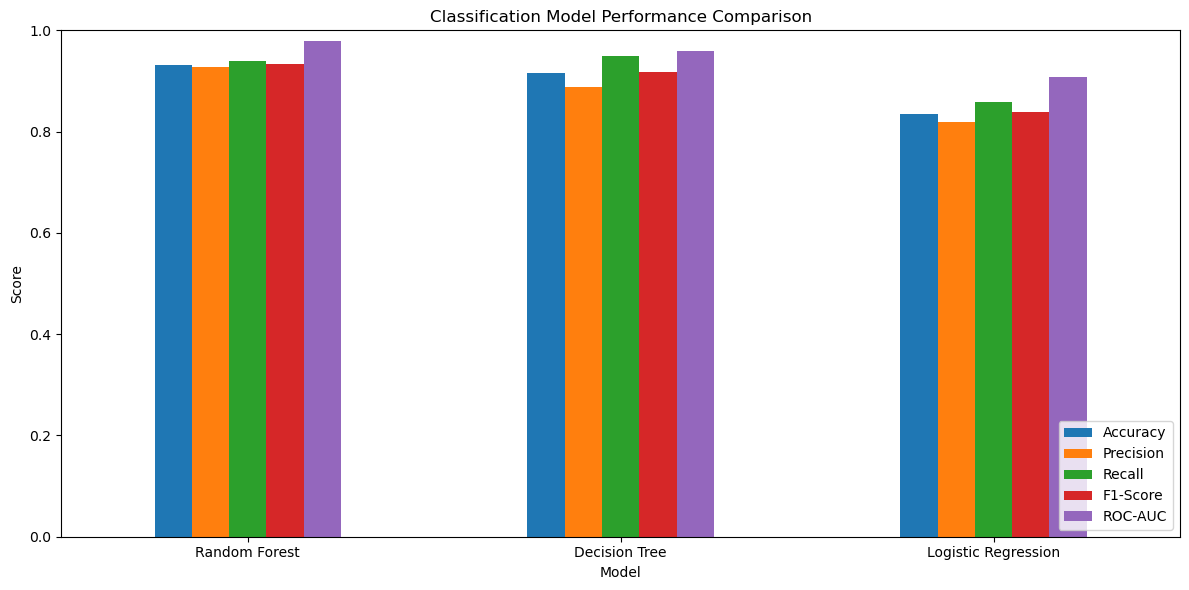

In [49]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

classification_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

<h3 style="color:white">Save Best Classification Model</h3>

In [50]:
import os
import joblib

os.makedirs("../models/classification", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/classification/random_forest_classifier.pkl"
)

print("Random Forest Classifier Saved Successfully!")

Random Forest Classifier Saved Successfully!


In [51]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/ChargingRecords_cleaned.csv"
)

threshold = df["Demand"].median()
classes = (df["Demand"] >= threshold).astype(int)

print("Demand threshold:", threshold)
print("\nClass counts:")
print(classes.value_counts().sort_index())

print("\nClass percentages:")
print(
    (classes.value_counts(normalize=True).sort_index() * 100).round(2)
)

Demand threshold: 14.1

Class counts:
Demand
0    36387
1    36439
Name: count, dtype: int64

Class percentages:
Demand
0    49.96
1    50.04
Name: proportion, dtype: float64


In [52]:
print(df.columns.tolist())

['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']


In [54]:
print("Demand data type:", df["Demand"].dtype)
print("\nUnique demand values:")
print(df["Demand"].nunique())

print("\nDemand value counts:")
print(df["Demand"].value_counts().head(10))

print("\nMissing values:", df["Demand"].isna().sum())

Demand data type: float64

Unique demand values:
6046

Demand value counts:
Demand
18.20    820
18.18    694
22.30    645
23.20    334
0.10     306
20.76    249
9.10     244
22.40    221
0.01     192
18.19    181
Name: count, dtype: int64

Missing values: 0


In [55]:
# Set the threshold
threshold = 14.1

# Create a separate binary target column
df["Demand_Class"] = (df["Demand"] >= threshold).astype("int8")

# Check class distribution
print("Demand threshold:", threshold)

print("\nClass counts:")
print(df["Demand_Class"].value_counts())

print("\nClass percentages:")
print(
    (df["Demand_Class"].value_counts(normalize=True) * 100).round(2)
)

Demand threshold: 14.1

Class counts:
Demand_Class
1    36439
0    36387
Name: count, dtype: int64

Class percentages:
Demand_Class
1    50.04
0    49.96
Name: proportion, dtype: float64


In [56]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Select features
X = df[
    [
        "ChargerCompany",
        "Location",
        "ChargerType",
        "StartDay",
        "Duration"
    ]
].copy()

# Binary target
y = df["Demand_Class"]

# Encode categorical columns
X = pd.get_dummies(
    X,
    columns=["Location", "StartDay"],
    drop_first=True,
    dtype="int8"
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

Training features: (58260, 381)
Testing features: (14566, 381)

Training class counts:
Demand_Class
1    29151
0    29109
Name: count, dtype: int64

Testing class counts:
Demand_Class
1    7288
0    7278
Name: count, dtype: int64


In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate model
print("Random Forest Classification Results")
print("------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Random Forest Classification Results
------------------------------------
Accuracy: 0.8666

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.86      7278
           1       0.86      0.88      0.87      7288

    accuracy                           0.87     14566
   macro avg       0.87      0.87      0.87     14566
weighted avg       0.87      0.87      0.87     14566

ROC-AUC: 0.9363

Confusion Matrix:
[[6210 1068]
 [ 875 6413]]


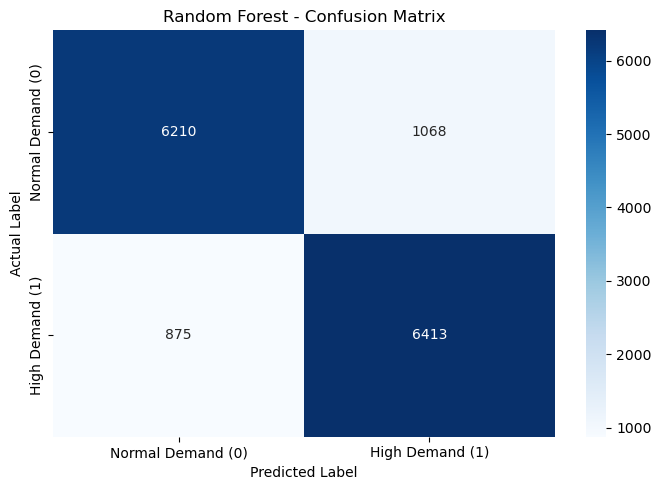

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Demand (0)", "High Demand (1)"],
    yticklabels=["Normal Demand (0)", "High Demand (1)"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [61]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

lr_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(max_iter=2000, random_state=42)
)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Results (Scaled)")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results (Scaled)
Accuracy: 0.832

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.81      0.83      7278
           1       0.82      0.85      0.84      7288

    accuracy                           0.83     14566
   macro avg       0.83      0.83      0.83     14566
weighted avg       0.83      0.83      0.83     14566

ROC-AUC: 0.9028

Confusion Matrix:
[[5905 1373]
 [1074 6214]]


In [62]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

# Initialize model
dt_model = DecisionTreeClassifier(
    max_depth=15,
    random_state=42
)

# Train model
dt_model.fit(X_train, y_train)

# Predictions
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Evaluate model
print("Decision Tree Classification Results")
print("------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_dt), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Classification Results
------------------------------------
Accuracy: 0.8829

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.85      0.88      7278
           1       0.86      0.92      0.89      7288

    accuracy                           0.88     14566
   macro avg       0.89      0.88      0.88     14566
weighted avg       0.89      0.88      0.88     14566

ROC-AUC: 0.9293

Confusion Matrix:
[[6153 1125]
 [ 580 6708]]


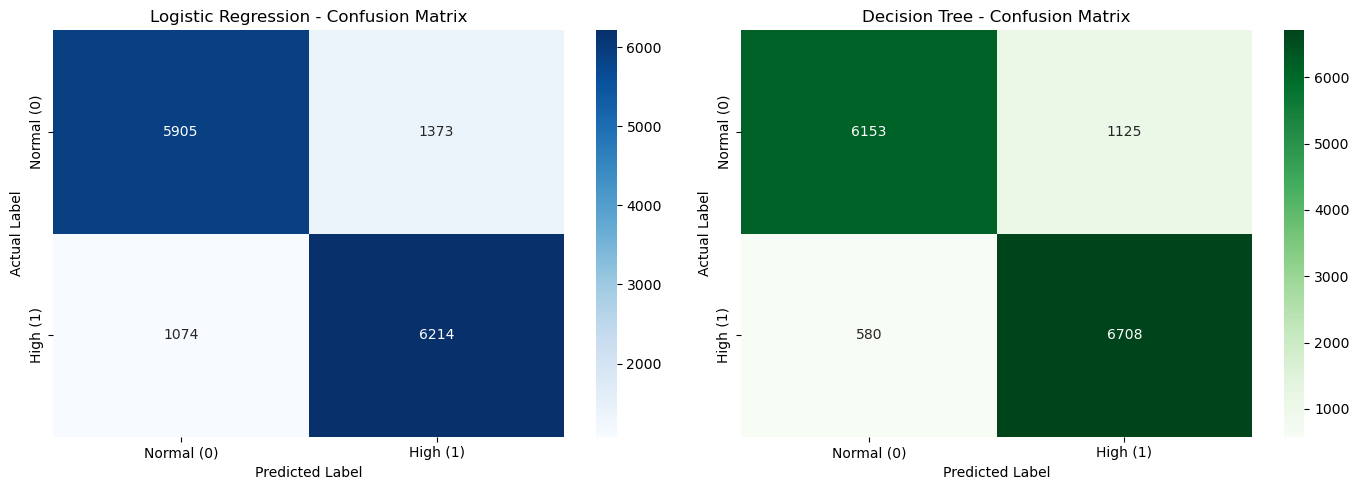

In [63]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal (0)", "High (1)"],
    yticklabels=["Normal (0)", "High (1)"],
    ax=axes[0]
)
axes[0].set_title("Logistic Regression - Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Normal (0)", "High (1)"],
    yticklabels=["Normal (0)", "High (1)"],
    ax=axes[1]
)
axes[1].set_title("Decision Tree - Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


In [66]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

# Initialize KNN model
knn_model = make_pipeline(
    StandardScaler(with_mean=False),
    KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
)

# Train model
knn_model.fit(X_train, y_train)

# Predictions
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

# Evaluate model
print("KNN Classification Results")
print("--------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_knn), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))


KNN Classification Results
--------------------------
Accuracy: 0.7701

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.76      0.77      7278
           1       0.77      0.78      0.77      7288

    accuracy                           0.77     14566
   macro avg       0.77      0.77      0.77     14566
weighted avg       0.77      0.77      0.77     14566

ROC-AUC: 0.8434

Confusion Matrix:
[[5536 1742]
 [1607 5681]]


In [67]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Initialize SVM
svm_model = make_pipeline(
    StandardScaler(with_mean=False),
    LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=42
    )
)

# Train the model
svm_model.fit(X_train, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test)
y_score_svm = svm_model.decision_function(X_test)

# Evaluate model
print("SVM Classification Results")
print("--------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("ROC-AUC:", round(roc_auc_score(y_test, y_score_svm), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))


SVM Classification Results
--------------------------
Accuracy: 0.7971

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.80      0.80      7278
           1       0.80      0.80      0.80      7288

    accuracy                           0.80     14566
   macro avg       0.80      0.80      0.80     14566
weighted avg       0.80      0.80      0.80     14566

ROC-AUC: 0.8776

Confusion Matrix:
[[5800 1478]
 [1478 5810]]


FINAL CLASSIFICATION MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
      Decision Tree    0.8829       0.86    0.92      0.89   0.9293
      Random Forest    0.8666       0.86    0.88      0.87   0.9363
Logistic Regression    0.8320       0.82    0.85      0.84   0.9028
                SVM    0.7971       0.80    0.80      0.80   0.8776
          KNN (k=5)    0.7701       0.77    0.78      0.77   0.8434


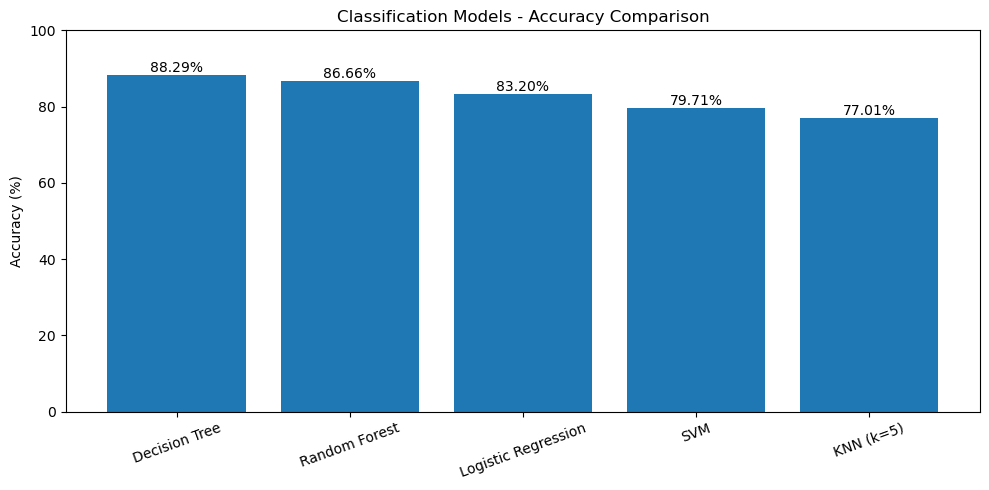

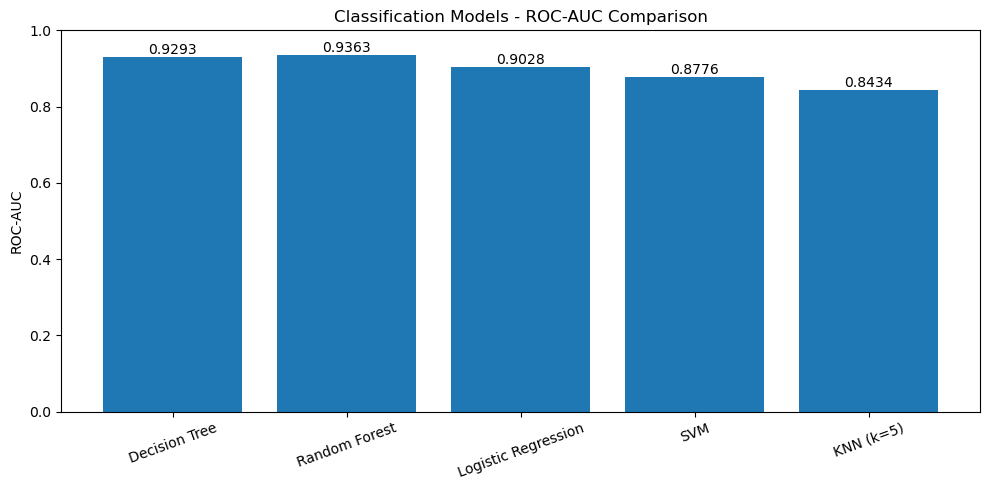

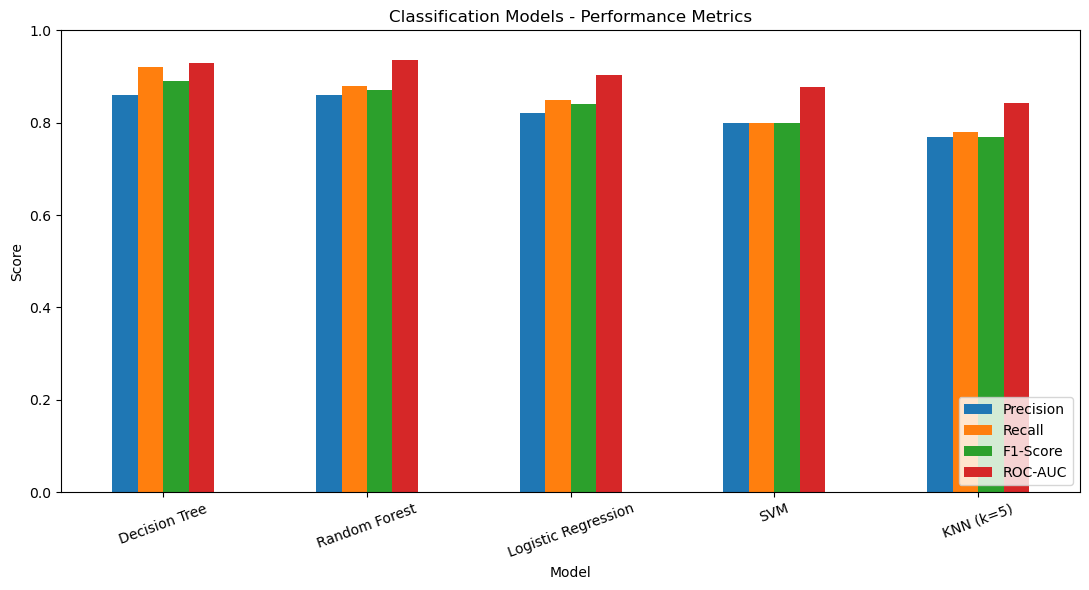

In [69]:

import pandas as pd
import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "SVM",
        "KNN (k=5)"
    ],
    "Accuracy": [0.8829, 0.8666, 0.8320, 0.7971, 0.7701],
    "Precision": [0.86, 0.86, 0.82, 0.80, 0.77],
    "Recall": [0.92, 0.88, 0.85, 0.80, 0.78],
    "F1-Score": [0.89, 0.87, 0.84, 0.80, 0.77],
    "ROC-AUC": [0.9293, 0.9363, 0.9028, 0.8776, 0.8434]
})

print("FINAL CLASSIFICATION MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

# Accuracy comparison
plt.figure(figsize=(10, 5))
bars = plt.bar(results_df["Model"], results_df["Accuracy"] * 100)
plt.bar_label(bars, fmt="%.2f%%")
plt.title("Classification Models - Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# ROC-AUC comparison
plt.figure(figsize=(10, 5))
bars = plt.bar(results_df["Model"], results_df["ROC-AUC"])
plt.bar_label(bars, fmt="%.4f")
plt.title("Classification Models - ROC-AUC Comparison")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Comparison of all evaluation metrics
results_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score", "ROC-AUC"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Classification Models - Performance Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Top 15 Important Features:
                    Feature  Importance
                   Duration    0.639540
                ChargerType    0.232414
             ChargerCompany    0.042795
            Location_resort    0.007154
         Location_apartment    0.005926
       Location_public area    0.002930
            Location_market    0.002709
           Location_company    0.002683
             Location_hotel    0.002591
Location_public institution    0.001724
        Location_restaurant    0.001359
           Location_camping    0.000759
        StartDay_2022-08-01    0.000628
        StartDay_2022-07-06    0.000622
        StartDay_2022-06-25    0.000566


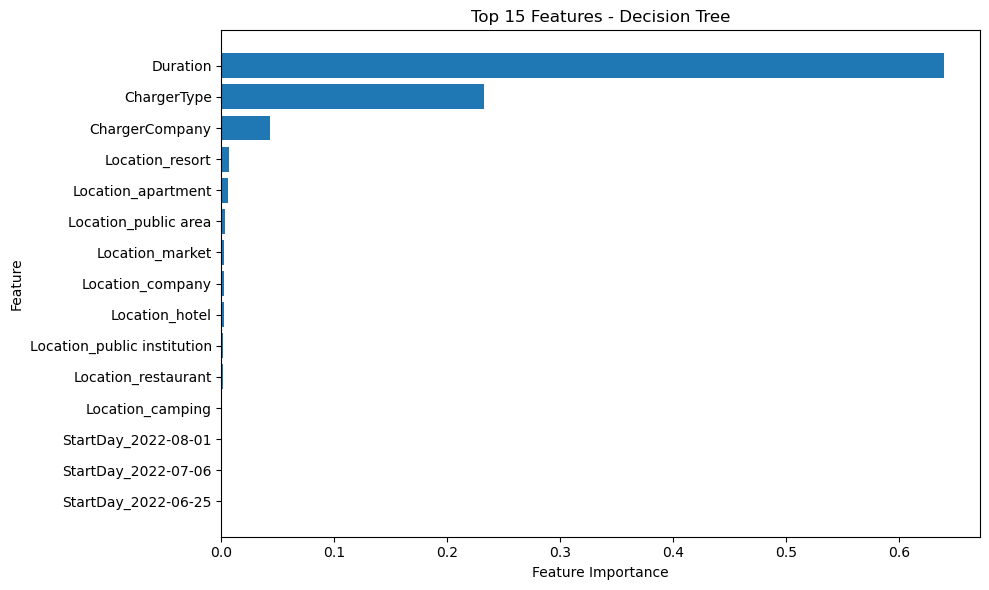

In [70]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained Decision Tree
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": dt_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

# Display top 15 features
print("Top 15 Important Features:")
print(feature_importance.head(15).to_string(index=False))

# Plot top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features - Decision Tree")
plt.tight_layout()
plt.show()


In [71]:

# Check the actual median and target threshold
actual_median = df["Demand"].median()

print("Actual Demand median:", actual_median)
print("Target threshold used:", 14.1)

# Check whether the target was created using the actual median
if actual_median == 14.1:
    print("Threshold check: Correct")
else:
    print("Threshold check: Review required")

# Compare Duration with continuous Demand
print("\nCorrelation between Duration and Demand:")
print(df[["Duration", "Demand"]].corr().round(4))

# Compare average duration across demand classes
print("\nAverage Duration by Demand Class:")
print(df.groupby("Demand_Class")["Duration"].agg(
    ["mean", "median", "min", "max"]
).round(2))


Actual Demand median: 14.1
Target threshold used: 14.1
Threshold check: Correct

Correlation between Duration and Demand:
          Duration  Demand
Duration    1.0000  0.6041
Demand      0.6041  1.0000

Average Duration by Demand Class:
                mean  median  min   max
Demand_Class                           
0              91.63    69.0    0  4006
1             219.34   189.0    0  4717


In [72]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report
)

# Remove Duration from the features
X_train_no_duration = X_train.drop(columns=["Duration"])
X_test_no_duration = X_test.drop(columns=["Duration"])

# Train a new Decision Tree
dt_no_duration = DecisionTreeClassifier(
    max_depth=15,
    random_state=42
)

dt_no_duration.fit(X_train_no_duration, y_train)

# Predictions
y_pred_no_duration = dt_no_duration.predict(X_test_no_duration)
y_prob_no_duration = dt_no_duration.predict_proba(
    X_test_no_duration
)[:, 1]

# Evaluation
print("Decision Tree WITHOUT Duration")
print("--------------------------------")
print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred_no_duration), 4)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob_no_duration), 4)
)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_no_duration))

# Compare with the original Decision Tree
print("Original accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print(
    "Accuracy without Duration:",
    round(accuracy_score(y_test, y_pred_no_duration), 4)
)


Decision Tree WITHOUT Duration
--------------------------------
Accuracy: 0.5913
ROC-AUC: 0.6225

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.39      0.49      7278
           1       0.57      0.79      0.66      7288

    accuracy                           0.59     14566
   macro avg       0.61      0.59      0.57     14566
weighted avg       0.61      0.59      0.57     14566

Original accuracy: 0.8829
Accuracy without Duration: 0.5913


In [73]:

# Inspect the relationship between Duration and Demand
print("Demand statistics by Duration range:")

df["Duration_Range"] = pd.cut(
    df["Duration"],
    bins=[-1, 30, 60, 120, 240, float("inf")],
    labels=["0-30", "31-60", "61-120", "121-240", "Above 240"]
)

print(
    df.groupby("Duration_Range", observed=True)["Demand"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

# Check whether Demand is approximately proportional to Duration
print("\nDemand-to-Duration ratio for positive durations:")
positive_duration = df[df["Duration"] > 0].copy()
positive_duration["Demand_per_Minute"] = (
    positive_duration["Demand"] / positive_duration["Duration"]
)

print(
    positive_duration["Demand_per_Minute"]
    .describe()
    .round(4)
)


Demand statistics by Duration range:
                count   mean  median   min    max
Duration_Range                                   
0-30            11156   6.31    3.13  0.01  58.45
31-60           13498  15.33   13.52  0.01  79.45
61-120          13350  11.07    9.40  0.10  96.35
121-240         21069  17.05   17.70  0.01  97.00
Above 240       13753  35.33   35.46  0.01  89.92

Demand-to-Duration ratio for positive durations:
count    72296.0000
mean         0.1954
std          0.3262
min          0.0000
25%          0.1000
50%          0.1114
75%          0.1179
max         34.5000
Name: Demand_per_Minute, dtype: float64


In [74]:

from sklearn.metrics import accuracy_score

# Decision Tree training vs testing performance
y_train_pred_dt = dt_model.predict(X_train)
y_test_pred_dt = dt_model.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred_dt)
test_accuracy = accuracy_score(y_test, y_test_pred_dt)

print("Decision Tree Overfitting Check")
print("--------------------------------")
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")
print(f"Accuracy Gap:      {train_accuracy - test_accuracy:.4f}")


Decision Tree Overfitting Check
--------------------------------
Training Accuracy: 0.9106
Testing Accuracy:  0.8829
Accuracy Gap:      0.0277


In [75]:

from sklearn.metrics import accuracy_score
import pandas as pd

models = {
    "Random Forest": rf_model,
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "KNN (k=5)": knn_model,
    "SVM": svm_model
}

comparison = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    comparison.append({
        "Model": name,
        "Training Accuracy": round(train_acc, 4),
        "Testing Accuracy": round(test_acc, 4),
        "Accuracy Gap": round(train_acc - test_acc, 4)
    })

comparison_df = pd.DataFrame(comparison)
print(comparison_df.to_string(index=False))


              Model  Training Accuracy  Testing Accuracy  Accuracy Gap
      Random Forest             0.9911            0.8666        0.1245
Logistic Regression             0.8302            0.8320       -0.0018
      Decision Tree             0.9106            0.8829        0.0277
          KNN (k=5)             0.8508            0.7701        0.0807
                SVM             0.7960            0.7971       -0.0011


In [76]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

rf_tuned = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train, y_train)

rf_train_pred = rf_tuned.predict(X_train)
rf_test_pred = rf_tuned.predict(X_test)
rf_test_prob = rf_tuned.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Results")
print("---------------------------")
print("Training Accuracy:",
      round(accuracy_score(y_train, rf_train_pred), 4))
print("Testing Accuracy:",
      round(accuracy_score(y_test, rf_test_pred), 4))
print("Accuracy Gap:",
      round(
          accuracy_score(y_train, rf_train_pred)
          - accuracy_score(y_test, rf_test_pred), 4
      ))
print("ROC-AUC:",
      round(roc_auc_score(y_test, rf_test_prob), 4))


Tuned Random Forest Results
---------------------------
Training Accuracy: 0.8719
Testing Accuracy: 0.8701
Accuracy Gap: 0.0018
ROC-AUC: 0.9262


Tuned Random Forest - Classification Report
              precision    recall  f1-score   support

           0       0.94      0.79      0.86      7278
           1       0.82      0.95      0.88      7288

    accuracy                           0.87     14566
   macro avg       0.88      0.87      0.87     14566
weighted avg       0.88      0.87      0.87     14566

Confusion Matrix:
[[5719 1559]
 [ 333 6955]]


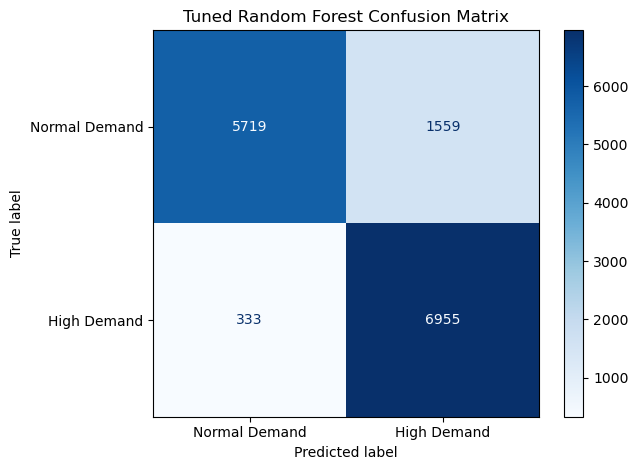

In [77]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Tuned Random Forest - Classification Report")
print(classification_report(y_test, rf_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_pred,
    display_labels=["Normal Demand", "High Demand"],
    cmap="Blues"
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()
